# **Composición con Bandas - Landsat 8**

In [1]:
import gdown
file_id = "1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT"
output_file = "Sur_Misiones_20240403.zip"

gdown.download(f"https://drive.google.com/uc?id={file_id}", output_file)

!unzip -qq Sur_Misiones_20240403.zip

Downloading...
From (original): https://drive.google.com/uc?id=1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT
From (redirected): https://drive.google.com/uc?id=1wP_81y_e-eaHdWW7Up2DUnI2P5l1_0HT&confirm=t&uuid=646cd1a1-f467-413a-a6ac-3841e9510e57
To: /content/Sur_Misiones_20240403.zip
100%|██████████| 620M/620M [00:07<00:00, 79.1MB/s]


In [2]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Función para leer una banda desde un archivo TIFF
def read_band(file_path):
    # Leer la imagen en escala de grises
    band = cv2.imread(file_path, cv2.IMREAD_UNCHANGED)
    if band is None:
        raise ValueError(f"Error leyendo la imagen en {file_path}")
    return band

# Función para normalizar el histograma usando el acumulado
def normalize_histogram(band):
    # Calcular el histograma
    # Resolución de bits del Landsat -> 2**16=65536
    hist, bins = np.histogram(band.flatten(), 65536, [0,65536])
    # Calcular el acumulado
    cdf = hist.cumsum()
    cdf_normalized = cdf * hist.max() / cdf.max()

    # Normalizar usando el CDF (distribución acumulativa de frecuencia)
    cdf_m = np.ma.masked_equal(cdf, 0)
    cdf_m = (cdf_m - cdf_m.min()) * 255 / (cdf_m.max() - cdf_m.min())
    cdf = np.ma.filled(cdf_m, 0).astype('uint8')

    # Aplicar la transformación de normalización
    band_normalized = cdf[band]
    return band_normalized

# Función para crear una imagen RGB a partir de las bandas seleccionadas
def create_rgb_image(red_band, green_band, blue_band):
    # Asegurarse de que todas las bandas estén normalizadas
    red_normalized = normalize_histogram(red_band)
    green_normalized = normalize_histogram(green_band)
    blue_normalized = normalize_histogram(blue_band)

    # Combinar las bandas en una imagen RGB
    rgb_image = cv2.merge([blue_normalized, green_normalized, red_normalized])

    return rgb_image

In [ ]:
 # Rutas a los archivos TIFF para las bandas
red_band_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B4.TIF"
green_band_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B3.TIF"
blue_band_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B2.TIF"

# Leer las bandas
red_band = read_band(red_band_path)
green_band = read_band(green_band_path)
blue_band = read_band(blue_band_path)

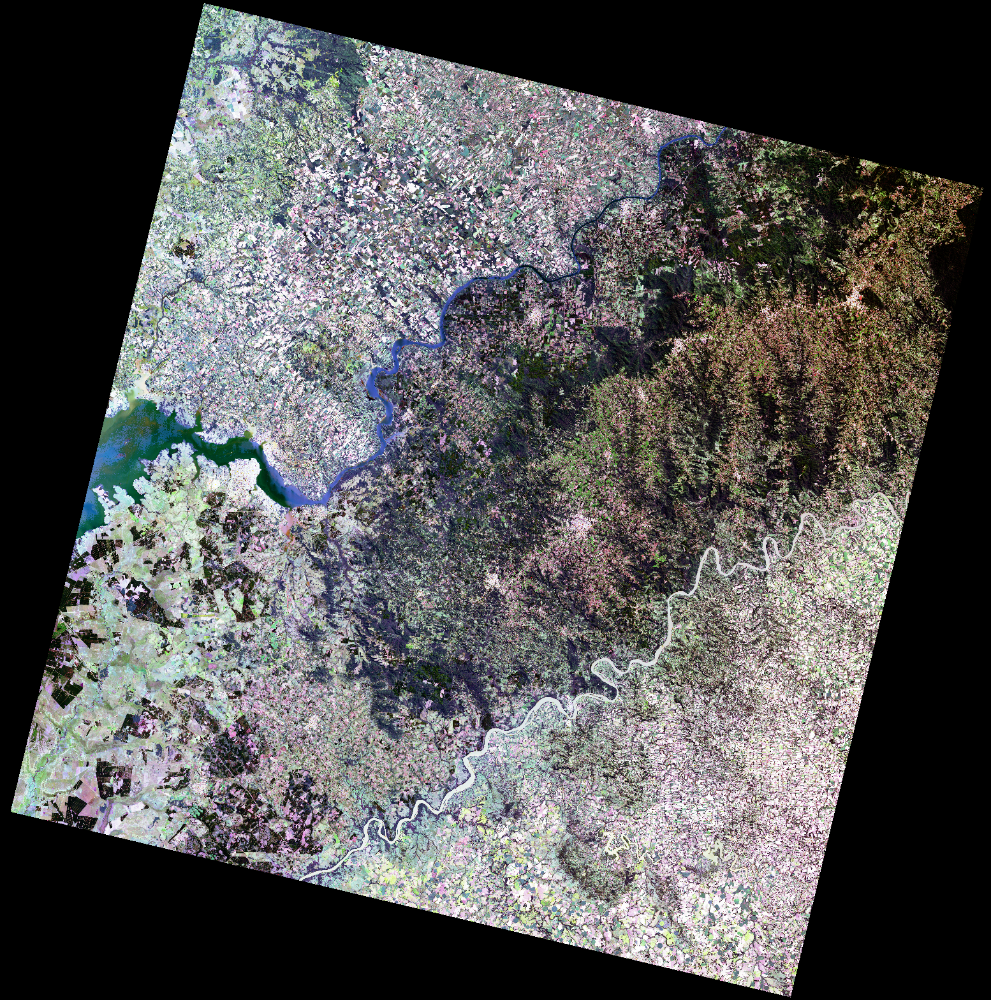

In [ ]:
# Crear la imagen RGB
rgb_image = create_rgb_image(red_band, green_band, blue_band)

# Reducir tamaño para mostrar
rgb_image = cv2.resize(rgb_image, (0, 0), fx=0.2, fy=0.2)

# Mostrar la imagen
cv2_imshow(rgb_image)

In [ ]:
# Rutas a los archivos TIF para las bandas
b7_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B7.TIF"
b6_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B6.TIF"
b4_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B4.TIF"

# Leer las bandas
b7 = read_band(b7_path)
b6 = read_band(b6_path)
b4 = read_band(b4_path)

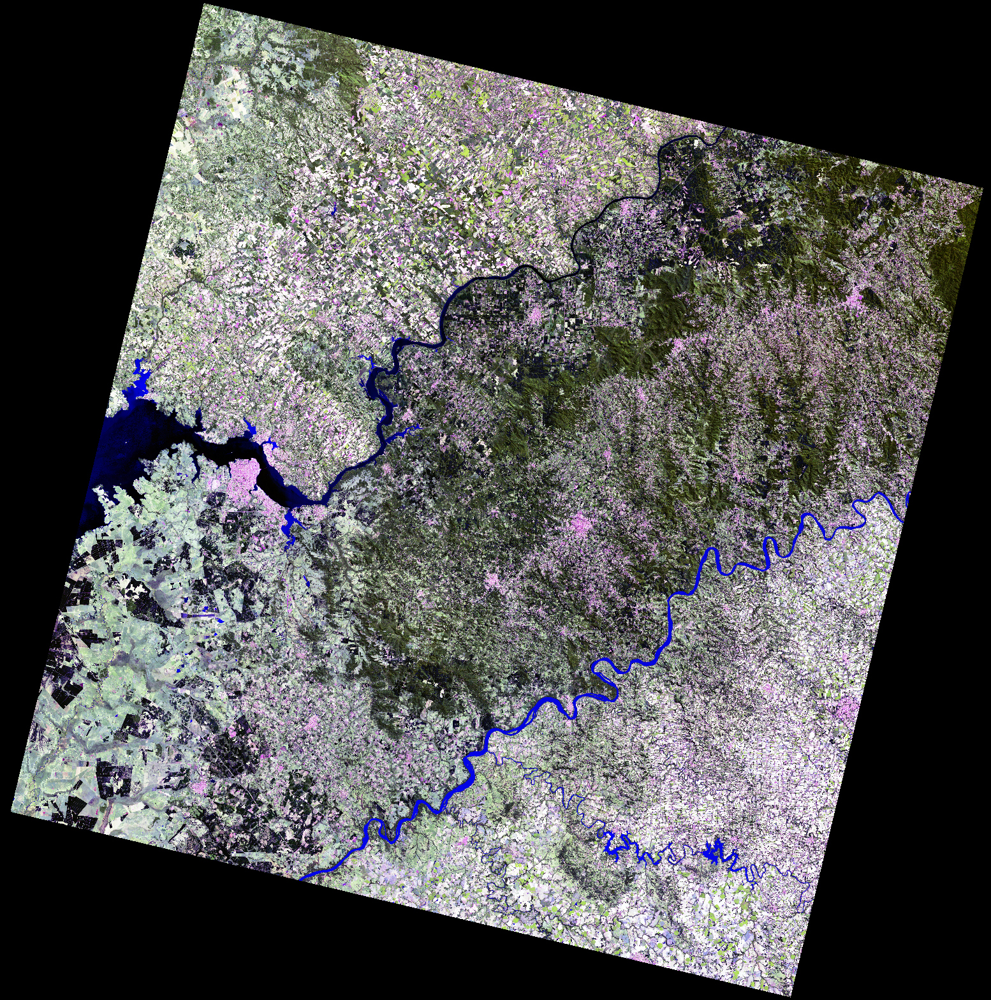

In [ ]:
falso_color = create_rgb_image(b7, b6, b4)

# Reducir tamaño para mostrar
falso_color = cv2.resize(falso_color, (0, 0), fx=0.2, fy=0.2)
cv2_imshow(falso_color)

`create_rgb_image` llama a `normalize_histogram` para cada una de las capas que recibe. Acá abajo se sobreescribe esa función (es medio una chanchada pero bueno) para ver y comparar rápidamente el efecto de una normalización diferente. Ya conocen las herramientas, apliquen las adecuadas...

In [3]:
def normalize_histogram(band, min_percentile=2, max_percentile=98):
    """
    Normaliza una banda de imagen utilizando umbrales de percentiles definidos por el usuario.

    Parameters:
    - band: np.ndarray. Imagen de la banda a normalizar.
    - min_percentile: float. Percentil mínimo para la normalización (por defecto 2%).
    - max_percentile: float. Percentil máximo para la normalización (por defecto 98%).

    Returns:
    - band_normalized: np.ndarray. Imagen de la banda normalizada.
    """

    # Calcular los valores de los percentiles especificados
    min_value = np.percentile(band, min_percentile)
    max_value = np.percentile(band, max_percentile)

    # Aplicar la normalización utilizando los percentiles
    band_normalized = np.clip(band, min_value, max_value)
    band_normalized = ((band_normalized - min_value) / (max_value - min_value)) * 255

    # Convertir a tipo de dato uint8
    band_normalized = band_normalized.astype(np.uint8)

    return band_normalized

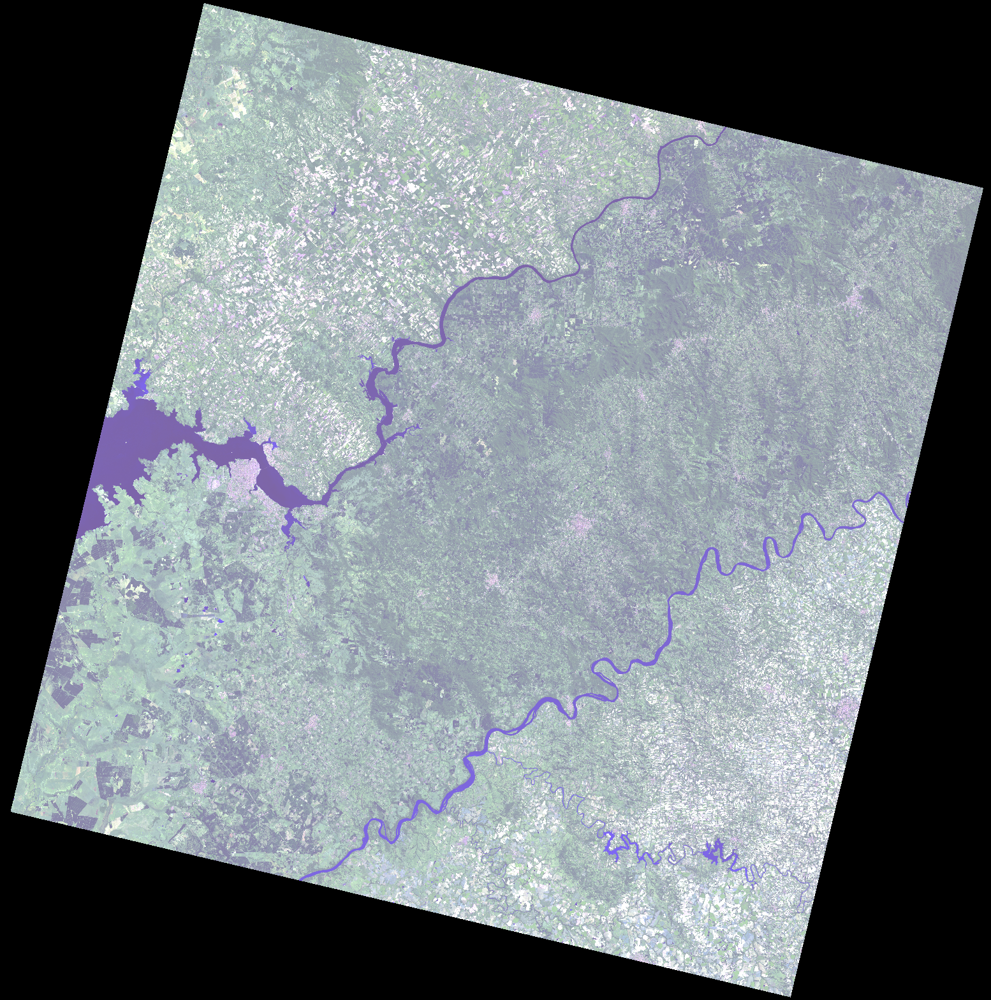

In [ ]:
falso_color = create_rgb_image(b7, b6, b4)

# Reducir tamaño para mostrar
falso_color = cv2.resize(falso_color, (0, 0), fx=0.2, fy=0.2)
cv2_imshow(falso_color)

In [4]:
def normalize_histogram(band, min_percentile=2, max_percentile=98):
    """
    Normaliza una banda de imagen utilizando los percentiles sobre la distribución acumulativa de frecuencia (CDF).

    Parameters:
    - band: np.ndarray. Imagen de la banda a normalizar.
    - min_percentile: float. Percentil mínimo para la normalización (por defecto 2%).
    - max_percentile: float. Percentil máximo para la normalización (por defecto 98%).

    Returns:
    - band_normalized: np.ndarray. Imagen de la banda normalizada.
    """

    # Calcular el histograma
    hist, bins = np.histogram(band.flatten(), 65536, [0, 65536])

    # Calcular la distribución acumulativa de frecuencia (CDF)
    cdf = hist.cumsum()

    # Normalizar la CDF
    cdf_normalized = cdf * 255 / cdf.max()

    # Calcular los valores de CDF correspondientes a los percentiles
    cdf_min = np.percentile(cdf_normalized, min_percentile)
    cdf_max = np.percentile(cdf_normalized, max_percentile)

    # Usar la CDF para mapear los valores originales de la imagen
    band_normalized = np.interp(band.flatten(), bins[:-1], cdf_normalized)

    # Aplicar los umbrales de normalización basados en la CDF
    band_normalized = np.clip(band_normalized, cdf_min, cdf_max)
    band_normalized = ((band_normalized - cdf_min) / (cdf_max - cdf_min)) * 255

    # Convertir a tipo de dato uint8
    band_normalized = band_normalized.reshape(band.shape).astype(np.uint8)

    return band_normalized


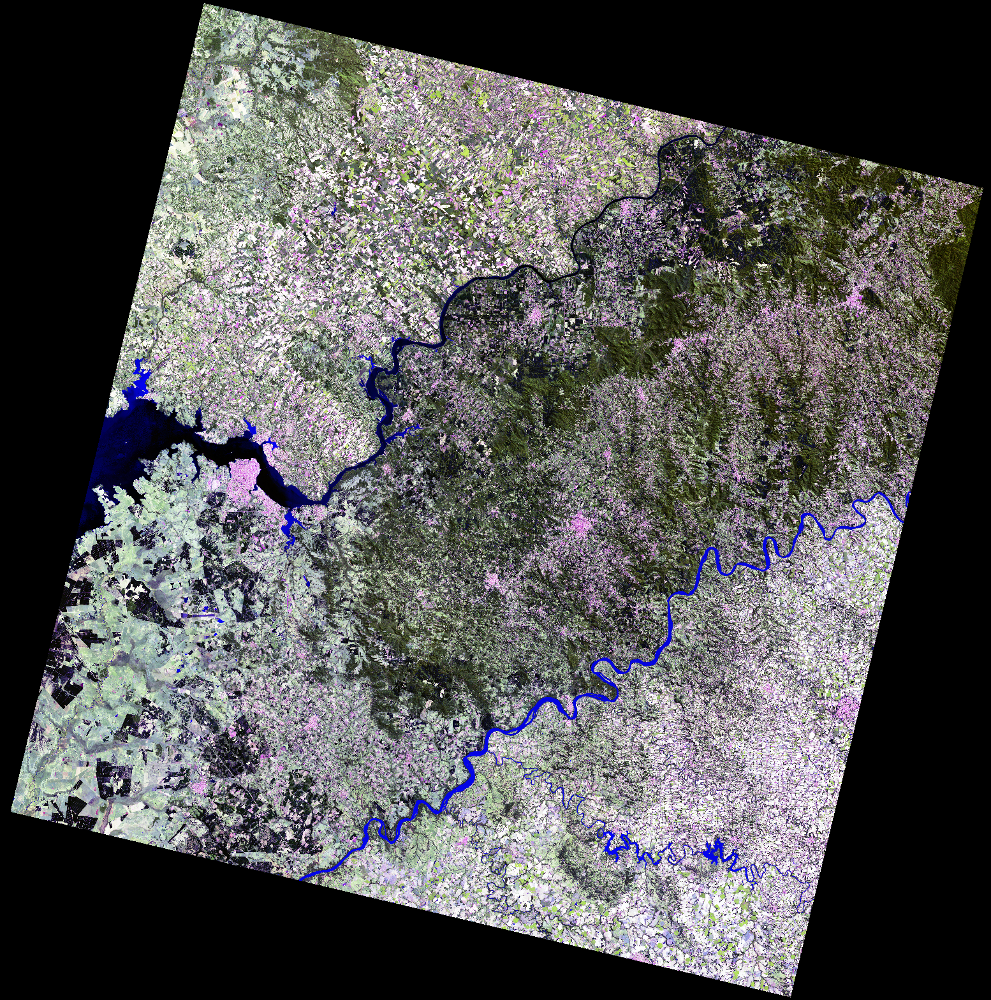

In [ ]:
falso_color = create_rgb_image(b7, b6, b4)

# Reducir tamaño para mostrar
falso_color = cv2.resize(falso_color, (0, 0), fx=0.2, fy=0.2)
cv2_imshow(falso_color)

In [ ]:
b5_path = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B5.TIF"

# Leer las bandas
b5 = read_band(b5_path)

suelo = create_rgb_image(b5, b6, b4)

# Reducir tamaño para mostrar
suelo = cv2.resize(suelo, (0, 0), fx=0.2, fy=0.2)
cv2_imshow(suelo)

In [ ]:
suelo.shape

(1568, 1554, 3)

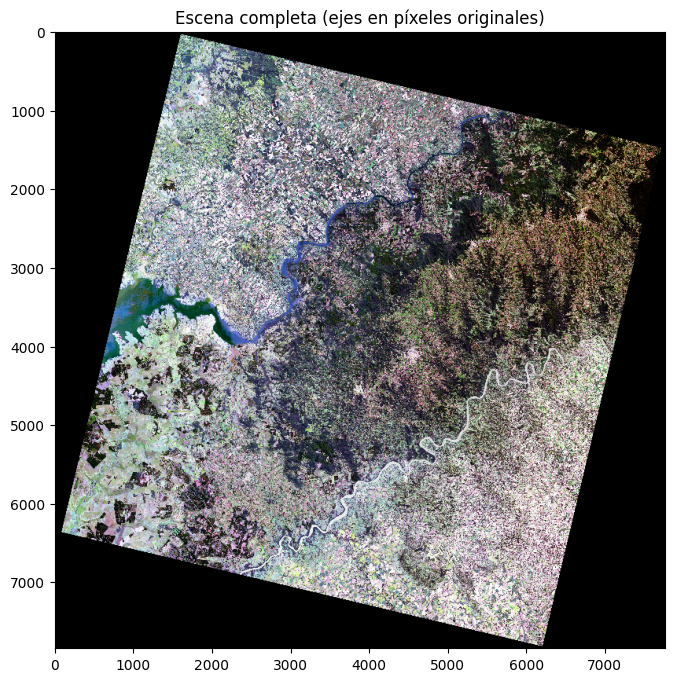

In [5]:
import matplotlib.pyplot as plt

BASE = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B{}.TIF"
bandas = {n: read_band(BASE.format(n)) for n in [2, 3, 4, 5, 6, 7]}

# --- 1) Elegir la ROI: vista previa de toda la escena con ejes en píxeles ---
prev = create_rgb_image(bandas[4], bandas[3] if 3 in bandas else bandas[4], bandas[2])
plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(cv2.resize(prev, (0, 0), fx=0.1, fy=0.1), cv2.COLOR_BGR2RGB),
           extent=[0, prev.shape[1], prev.shape[0], 0])
plt.title("Escena completa (ejes en píxeles originales)")
plt.show()

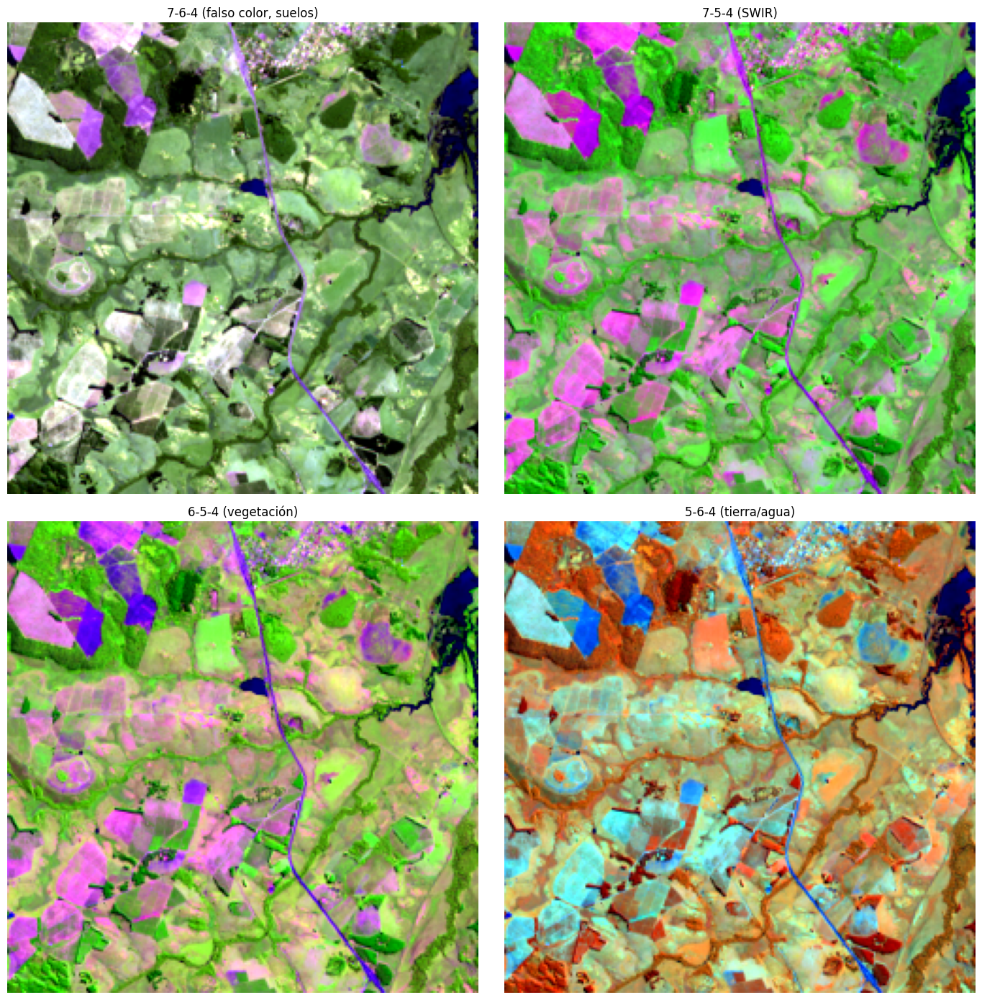

In [6]:
# --- 2) Recorte (ajustá estos valores según tu zona) ---
y0, y1, x0, x1 = 4250, 4500, 2000, 2250
roi = {n: b[y0:y1, x0:x1] for n, b in bandas.items()}

# --- 3) Estiramiento lineal por percentiles, ignorando nodata (0) ---
def stretch(band, pmin=2, pmax=98):
    valid = band[band > 0]
    lo, hi = np.percentile(valid, [pmin, pmax])
    out = np.clip((band.astype(np.float32) - lo) / (hi - lo), 0, 1)
    return (out * 255).astype(np.uint8)

def rgb(r, g, b):
    return np.dstack([stretch(r), stretch(g), stretch(b)])   # RGB para matplotlib

# --- 4) Composiciones a comparar ---
comps = {
    "7-6-4 (falso color, suelos)": (7, 6, 4),
    "7-5-4 (SWIR)":                (7, 5, 4),
    "6-5-4 (vegetación)":          (6, 5, 4),
    "5-6-4 (tierra/agua)":         (5, 6, 4),
}
fig, axs = plt.subplots(2, 2, figsize=(14, 14))
for ax, (titulo, (r, g, b)) in zip(axs.ravel(), comps.items()):
    ax.imshow(rgb(roi[r], roi[g], roi[b]))
    ax.set_title(titulo); ax.axis("off")
plt.tight_layout(); plt.show()

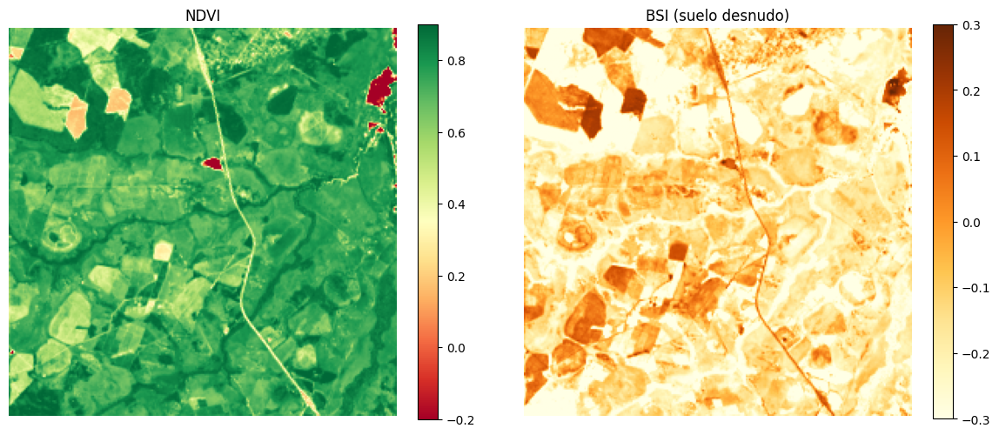

In [ ]:
# --- 5) Índices de apoyo ---
def refl(b):  # factor de escala Landsat C2 L2 SR
    return b.astype(np.float32) * 0.0000275 - 0.2

blue, red, nir, swir1 = (refl(roi[n]) for n in (2, 4, 5, 6))
eps = 1e-6
ndvi = (nir - red) / (nir + red + eps)
bsi  = ((swir1 + red) - (nir + blue)) / ((swir1 + red) + (nir + blue) + eps)   # Bare Soil Index

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
im0 = axs[0].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.9); axs[0].set_title("NDVI")
im1 = axs[1].imshow(bsi,  cmap="YlOrBr", vmin=-0.3, vmax=0.3); axs[1].set_title("BSI (suelo desnudo)")
for im, ax in zip((im0, im1), axs):
    ax.axis("off"); plt.colorbar(im, ax=ax, fraction=0.046)
plt.show()

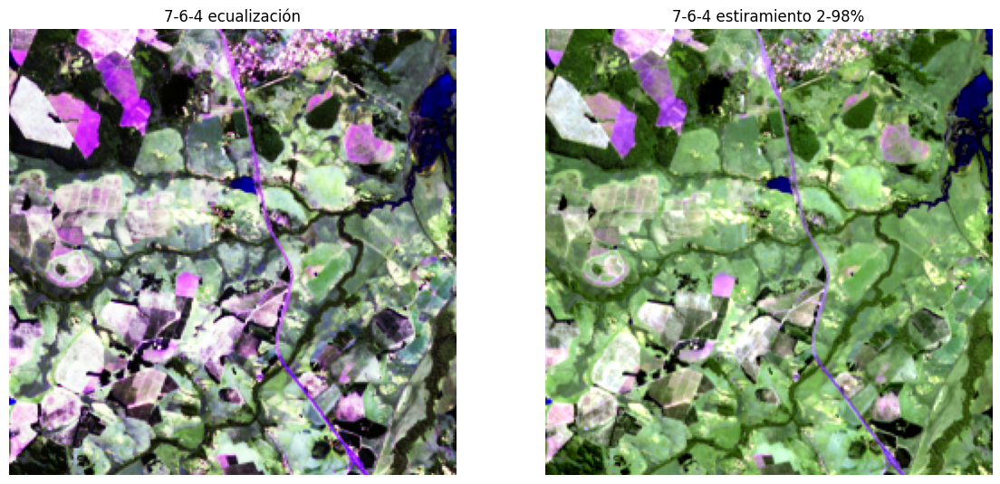

In [ ]:
def equalize(band):
    valid = band[band > 0]
    hist, _ = np.histogram(valid, 65536, [0, 65536])
    cdf = hist.cumsum()
    cmin = cdf[cdf > 0].min()
    lut = np.clip((cdf - cmin) * 255 / (cdf.max() - cmin), 0, 255).astype(np.uint8)
    out = lut[band]
    out[band == 0] = 0
    return out

r, g, b = roi[7], roi[6], roi[4]
eq  = np.dstack([equalize(r), equalize(g), equalize(b)])
lin = np.dstack([stretch(r),  stretch(g),  stretch(b)])

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
axs[0].imshow(eq);  axs[0].set_title("7-6-4 ecualización")
axs[1].imshow(lin); axs[1].set_title("7-6-4 estiramiento 2-98%")
for ax in axs: ax.axis("off")
plt.show()

In [7]:
# Parches de muestra (y0, y1, x0, x1) relativos a la ROI: ajustalos mirando tu imagen
muestras = {
    "Suelo desnudo": (100, 120, 200, 220),
    "Vegetación":    (400, 420, 500, 520),
    "Agua":          (700, 720, 100, 120),
}
orden = [2, 4, 5, 6, 7]
etiquetas = ["B2 Azul", "B4 Rojo", "B5 NIR", "B6 SWIR1", "B7 SWIR2"]

plt.figure(figsize=(8, 5))
for nombre, (a, b, c, d) in muestras.items():
    firma = [refl(roi[n][a:b, c:d]).mean() for n in orden]
    plt.plot(etiquetas, firma, marker="o", label=nombre)
plt.ylabel("Reflectancia"); plt.title("Firmas espectrales"); plt.legend(); plt.grid(alpha=.3)
plt.show()

NameError: name 'refl' is not defined

<Figure size 800x500 with 0 Axes>

CRS de la escena: EPSG:32621
ROI -> lat: -27.5973 a -27.5290 | lon: -55.8933 a -55.8167



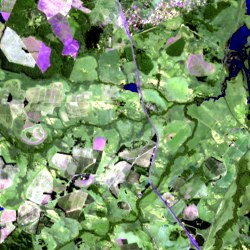

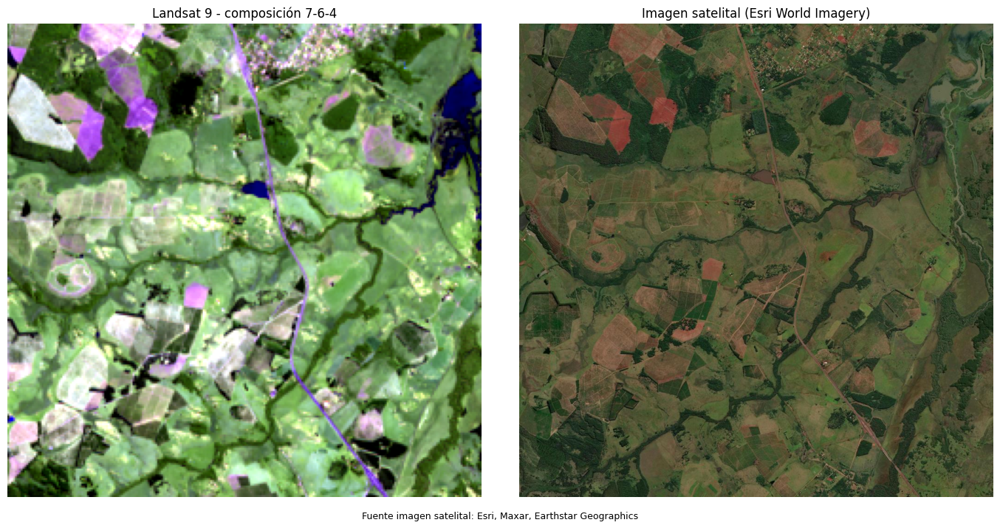

In [8]:
!pip install -q rasterio contextily folium

import rasterio
from rasterio.windows import Window, bounds as win_bounds
from rasterio.warp import transform_bounds
import folium
import contextily as cx
from IPython.display import display

# --- 1) Coordenadas geográficas de la ROI (mismos y0, y1, x0, x1 del recorte) ---
with rasterio.open(BASE.format(4)) as src:
    win = Window(x0, y0, x1 - x0, y1 - y0)
    l, b, r, t = win_bounds(win, src.transform)                # en el CRS de la escena (UTM)
    w, s, e, n = transform_bounds(src.crs, "EPSG:4326", l, b, r, t)

print(f"CRS de la escena: {src.crs}")
print(f"ROI -> lat: {s:.4f} a {n:.4f} | lon: {w:.4f} a {e:.4f}")

# Composición a comparar (la 7-6-4 de suelos)
comp = rgb(roi[7], roi[6], roi[4])

# --- 2) Mapa interactivo: capa satelital de Esri + composición superpuesta ---
m = folium.Map(
    location=[(s + n) / 2, (w + e) / 2],
    zoom_start=13,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics",
)
folium.raster_layers.ImageOverlay(
    image=comp, bounds=[[s, w], [n, e]], opacity=0.7, name="Composición 7-6-4"
).add_to(m)
folium.Rectangle([[s, w], [n, e]], color="red", weight=2, fill=False, name="ROI").add_to(m)
folium.LayerControl().add_to(m)
display(m)   # usá el control de capas para prender/apagar la composición

# --- 3) Comparación estática lado a lado (para el informe), con la misma capa satelital ---
cx.tile._clear_cache()
cx.tile.USER_AGENT = "LabMultiespectral-UNaM/1.0 (estudiante UNaM; uso academico)"

img_sat, _ = cx.bounds2img(w, s, e, n, ll=True, source=cx.providers.Esri.WorldImagery)

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
axs[0].imshow(comp);    axs[0].set_title("Landsat 9 - composición 7-6-4")
axs[1].imshow(img_sat); axs[1].set_title("Imagen satelital (Esri World Imagery)")
for ax in axs: ax.axis("off")
fig.text(0.5, 0.02, "Fuente imagen satelital: Esri, Maxar, Earthstar Geographics",
         ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("roi_vs_satelite.png", dpi=200, bbox_inches="tight")
plt.show()

# Nuevo

In [9]:
import itertools
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B{}.TIF"

# ROI en píxeles de la escena completa (ajustá a tu zona)
y0, y1, x0, x1 = 4250, 4500, 2000, 2250

BANDAS = [2, 3, 4, 5, 6, 7]

COMPOSICIONES = {
    "7-6-4 falso color":      (7, 6, 4),
    "7-5-4 SWIR":             (7, 5, 4),
    "6-5-4 vegetación":       (6, 5, 4),
    "5-6-4 tierra/agua":      (5, 6, 4),
    "5-4-3 suelo desnudo":    (5, 4, 3),
    "test":                   (5, 7, 4),
}

# Parches de muestra (a, b, c, d) = filas a:b, columnas c:d RELATIVAS a la ROI.
# Ajustalos mirando la imagen; sirven para medir separabilidad entre coberturas.
PARCHES = {
    "suelo desnudo": (100, 120, 200, 220),
    "vegetación":    (400, 420, 500, 520),
    "agua":          (700, 720, 100, 120),
}

def read_roi(n):
    b = cv2.imread(BASE.format(n), cv2.IMREAD_UNCHANGED)
    if b is None:
        raise ValueError(f"No se pudo leer la banda {n}")
    return b[y0:y1, x0:x1].copy()

roi = {n: read_roi(n) for n in BANDAS}
valid = np.all([roi[n] > 0 for n in BANDAS], axis=0)     # excluye nodata (0)
print(f"ROI {valid.shape} | píxeles válidos: {valid.mean()*100:.1f}%")

ROI (250, 250) | píxeles válidos: 100.0%


In [10]:
def _scale(x, lo, hi):
    return np.clip((x.astype(np.float32) - lo) / (hi - lo + 1e-9), 0, 1)

def m_minmax(bs, valid):
    return [_scale(b, b[valid].min(), b[valid].max()) for b in bs]

def make_percentil(p_lo=2, p_hi=98, conjunto=False):
    """Estiramiento lineal por percentiles. conjunto=True usa los mismos límites para
    las 3 bandas (conserva las proporciones entre bandas); False estira cada una por separado."""
    def f(bs, valid):
        if conjunto:
            lo = min(np.percentile(b[valid], p_lo) for b in bs)
            hi = max(np.percentile(b[valid], p_hi) for b in bs)
            return [_scale(b, lo, hi) for b in bs]
        return [_scale(b, *np.percentile(b[valid], [p_lo, p_hi])) for b in bs]
    return f

def make_gamma(g, p_lo=2, p_hi=98):
    base = make_percentil(p_lo, p_hi)
    return lambda bs, valid: [x ** g for x in base(bs, valid)]

def m_log(bs, valid, k=50):
    base = make_percentil(2, 98)(bs, valid)
    return [np.log1p(k * x) / np.log1p(k) for x in base]

def m_ecualizar(bs, valid):
    out = []
    for b in bs:
        hist, _ = np.histogram(b[valid], bins=65536, range=(0, 65536))
        cdf = hist.cumsum().astype(np.float64)
        cmin = cdf[cdf > 0].min()
        cdf = (cdf - cmin) / (cdf.max() - cmin)
        out.append(np.clip(cdf[b], 0, 1).astype(np.float32))
    return out

def m_clahe(bs, valid, clip=2.0, grid=8):
    base = make_percentil(2, 98)(bs, valid)
    clahe = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid))
    return [clahe.apply((x * 255).astype(np.uint8)).astype(np.float32) / 255 for x in base]

METODOS = {
    "Min-Max":                  m_minmax,
    "Percentil 2-98":           make_percentil(2, 98),
    "Percentil 2-98 conjunto":  make_percentil(2, 98, conjunto=True),
    "Percentil 5-95":           make_percentil(5, 95),
    "Gamma 0.7":                make_gamma(0.7),
    "Log":                      m_log,
    "Ecualización":             m_ecualizar,
    "CLAHE":                    lambda bs, v: m_clahe(bs, v, 2.0, 8),
}

def componer(comp, metodo):
    """Devuelve imagen RGB float [0,1] (H, W, 3) para una composición (R,G,B) y un método."""
    bs = [roi[n] for n in comp]
    img = np.dstack(METODOS[metodo](bs, valid))
    img[~valid] = 0
    return img

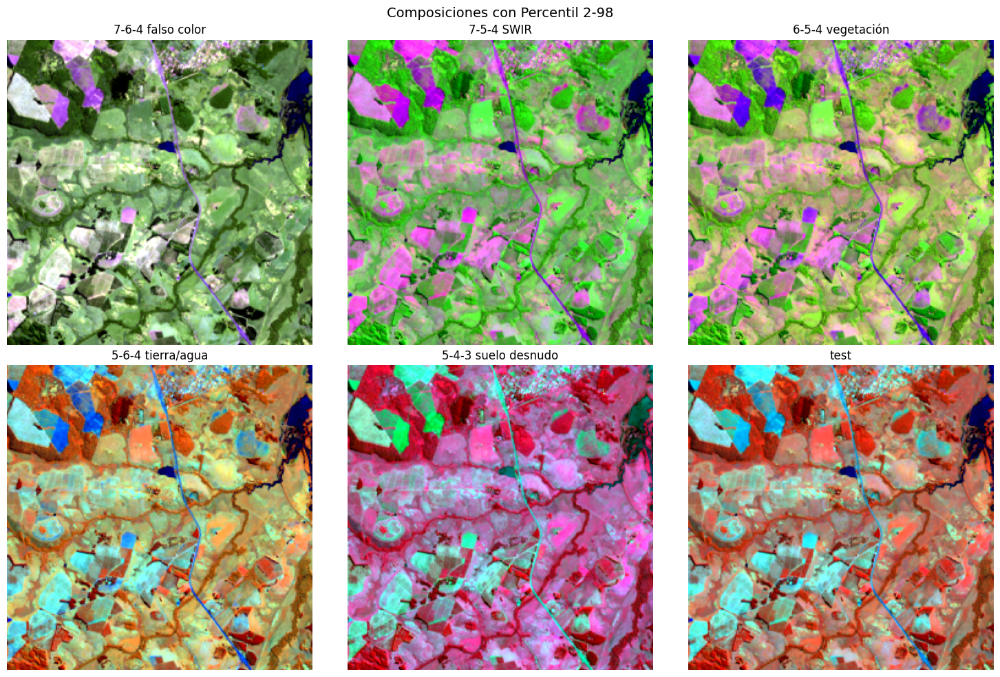

In [11]:
def _grilla(n_imgs, cols=3, lado=5):
    """Crea una grilla de a lo sumo 3 columnas y devuelve (fig, lista_de_ejes)."""
    cols = max(1, min(cols, 3, n_imgs))                 # nunca más de 3 columnas
    filas = int(np.ceil(n_imgs / cols))
    fig, axs = plt.subplots(filas, cols, figsize=(lado * cols, lado * filas), squeeze=False)
    axs = axs.ravel()
    for ax in axs[n_imgs:]:                              # apaga los ejes sobrantes
        ax.axis("off")
    return fig, axs[:n_imgs]

def comparar_metodos(nombre_comp, cols=3, guardar=True):
    """Misma composición con todos los métodos (máx. 3 columnas)."""
    comp = COMPOSICIONES[nombre_comp]
    fig, axs = _grilla(len(METODOS), cols)
    for ax, m in zip(axs, METODOS):
        ax.imshow(componer(comp, m)); ax.set_title(m); ax.axis("off")
    fig.suptitle(f"Composición {nombre_comp}: comparación de métodos", fontsize=14)
    plt.tight_layout()
    if guardar: plt.savefig(f"metodos_{comp[0]}{comp[1]}{comp[2]}.png", dpi=150, bbox_inches="tight")
    plt.show()

def comparar_composiciones(metodo, cols=3, guardar=True):
    """Todas las composiciones con un mismo método (máx. 3 columnas)."""
    fig, axs = _grilla(len(COMPOSICIONES), cols)
    for ax, (nombre, comp) in zip(axs, COMPOSICIONES.items()):
        ax.imshow(componer(comp, metodo)); ax.set_title(nombre); ax.axis("off")
    fig.suptitle(f"Composiciones con {metodo}", fontsize=14)
    plt.tight_layout()
    if guardar: plt.savefig(f"composiciones_{metodo.replace(' ', '_')}.png", dpi=150, bbox_inches="tight")
    plt.show()

# Ejemplos de uso:
#comparar_metodos("7-6-4 falso color")
comparar_composiciones("Percentil 2-98")

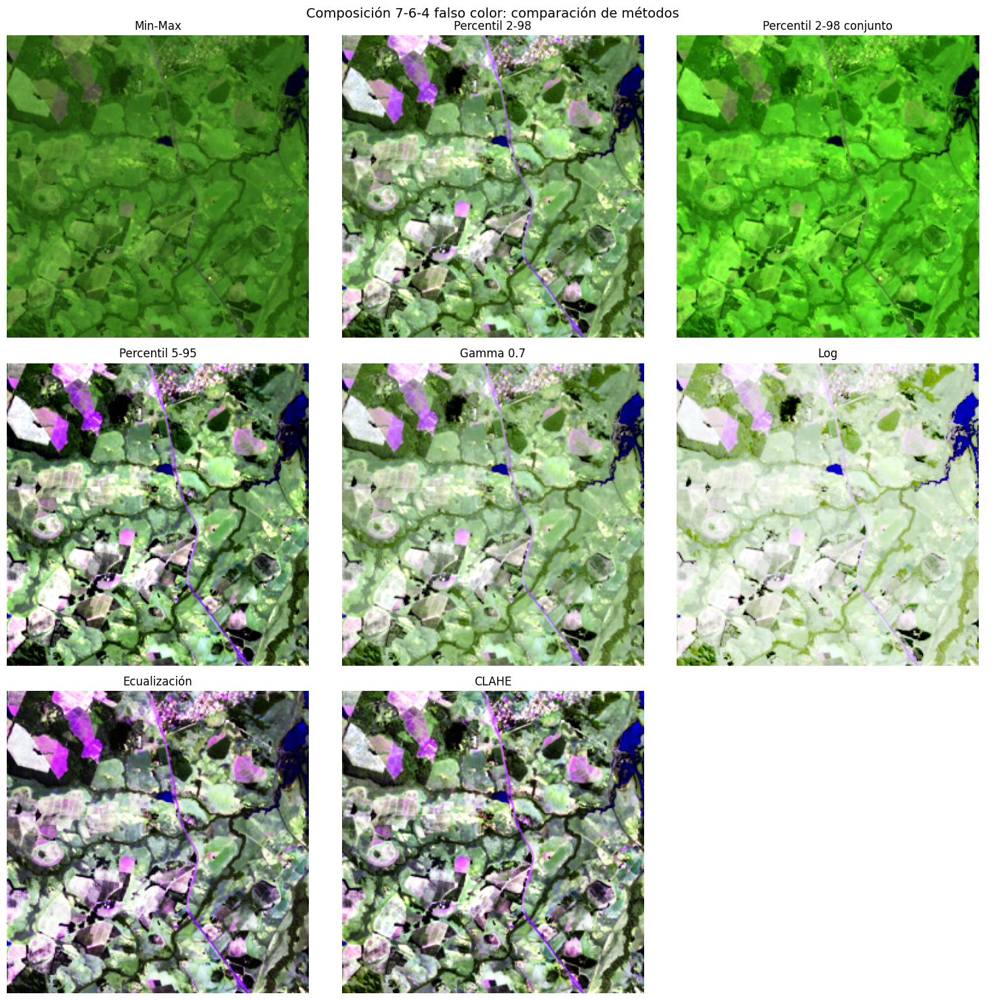

In [ ]:
comparar_metodos("7-6-4 falso color")

ROI (100, 100) | píxeles válidos: 100.0%


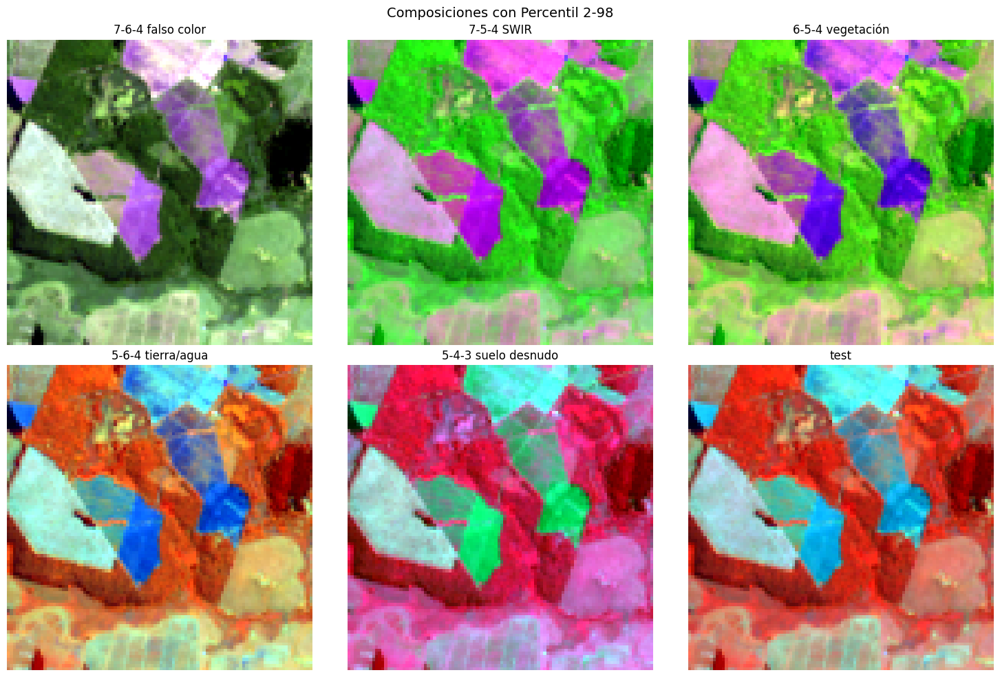

In [12]:
import itertools
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = "/content/Sur_Misiones_20240403/LC09_L2SP_224079_20240403_20240404_02_T1_SR_B{}.TIF"

# ROI en píxeles de la escena completa (ajustá a tu zona)
y0, y1, x0, x1 = 4250, 4350, 2000, 2100

BANDAS = [2, 3, 4, 5, 6, 7]

COMPOSICIONES = {
    "7-6-4 falso color":      (7, 6, 4),
    "7-5-4 SWIR":             (7, 5, 4),
    "6-5-4 vegetación":       (6, 5, 4),
    "5-6-4 tierra/agua":      (5, 6, 4),
    "5-4-3 suelo desnudo":    (5, 4, 3),
    "test":                   (5, 7, 4),
}

# Parches de muestra (a, b, c, d) = filas a:b, columnas c:d RELATIVAS a la ROI.
# Ajustalos mirando la imagen; sirven para medir separabilidad entre coberturas.
PARCHES = {
    "suelo desnudo": (100, 120, 200, 220),
    "vegetación":    (400, 420, 500, 520),
    "agua":          (700, 720, 100, 120),
}

def read_roi(n):
    b = cv2.imread(BASE.format(n), cv2.IMREAD_UNCHANGED)
    if b is None:
        raise ValueError(f"No se pudo leer la banda {n}")
    return b[y0:y1, x0:x1].copy()

roi = {n: read_roi(n) for n in BANDAS}
valid = np.all([roi[n] > 0 for n in BANDAS], axis=0)     # excluye nodata (0)
print(f"ROI {valid.shape} | píxeles válidos: {valid.mean()*100:.1f}%")
comparar_composiciones("Percentil 2-98")

CRS de la escena: EPSG:32621
ROI -> lat: -27.5567 a -27.5294 | lon: -55.8933 a -55.8627



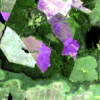

Imagen satelital recortada: 715x718 px | composición: 100x100 px


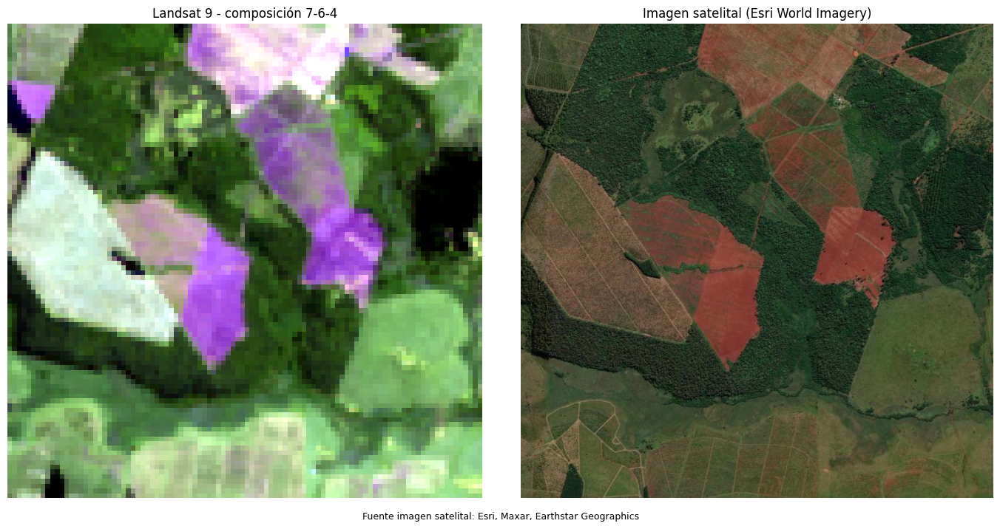

In [13]:
!pip install -q rasterio contextily folium

import rasterio
from rasterio.windows import Window, bounds as win_bounds
from rasterio.warp import transform_bounds
import folium
import contextily as cx
from IPython.display import display

# --- 1) Coordenadas geográficas de la ROI (mismos y0, y1, x0, x1 del recorte) ---
with rasterio.open(BASE.format(4)) as src:
    win = Window(x0, y0, x1 - x0, y1 - y0)
    l, b, r, t = win_bounds(win, src.transform)                # en el CRS de la escena (UTM)
    w, s, e, n = transform_bounds(src.crs, "EPSG:4326", l, b, r, t)

print(f"CRS de la escena: {src.crs}")
print(f"ROI -> lat: {s:.4f} a {n:.4f} | lon: {w:.4f} a {e:.4f}")

# Composición a comparar (la 7-6-4 de suelos)
comp = rgb(roi[7], roi[6], roi[4])

# --- 2) Mapa interactivo: capa satelital de Esri + composición superpuesta ---
m = folium.Map(
    location=[(s + n) / 2, (w + e) / 2],
    zoom_start=13,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics",
)
folium.raster_layers.ImageOverlay(
    image=comp, bounds=[[s, w], [n, e]], opacity=0.7, name="Composición 7-6-4"
).add_to(m)
folium.Rectangle([[s, w], [n, e]], color="red", weight=2, fill=False, name="ROI").add_to(m)
folium.LayerControl().add_to(m)
display(m)   # usá el control de capas para prender/apagar la composición

# --- 3) Comparación estática lado a lado (para el informe), con la misma capa satelital ---
cx.tile._clear_cache()
cx.tile.USER_AGENT = "LabMultiespectral-UNaM/1.0 (estudiante UNaM; uso academico)"

img_sat, ext = cx.bounds2img(w, s, e, n, ll=True, source=cx.providers.Esri.WorldImagery)

# El mosaico trae teselas completas: se recorta a los límites exactos de la ROI.
xmin, xmax, ymin, ymax = ext                                   # extent del mosaico (EPSG:3857)
rx0, ry0, rx1, ry1 = transform_bounds("EPSG:4326", "EPSG:3857", w, s, e, n)
H, W = img_sat.shape[:2]
c0 = int(round((rx0 - xmin) / (xmax - xmin) * W))
c1 = int(round((rx1 - xmin) / (xmax - xmin) * W))
f0 = int(round((ymax - ry1) / (ymax - ymin) * H))
f1 = int(round((ymax - ry0) / (ymax - ymin) * H))
img_sat = img_sat[f0:f1, c0:c1, :3]
print(f"Imagen satelital recortada: {img_sat.shape[1]}x{img_sat.shape[0]} px | composición: {comp.shape[1]}x{comp.shape[0]} px")

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
axs[0].imshow(comp);    axs[0].set_title("Landsat 9 - composición 7-6-4")
axs[1].imshow(img_sat); axs[1].set_title("Imagen satelital (Esri World Imagery)")
for ax in axs: ax.axis("off")
fig.text(0.5, 0.02, "Fuente imagen satelital: Esri, Maxar, Earthstar Geographics",
         ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("roi_vs_satelite.png", dpi=200, bbox_inches="tight")
plt.show()

CRS de la escena: EPSG:32621
ROI -> lat: -27.5567 a -27.5294 | lon: -55.8933 a -55.8627



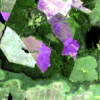

/tmp/ipykernel_1897/3117823597.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0.04, 1, 1])


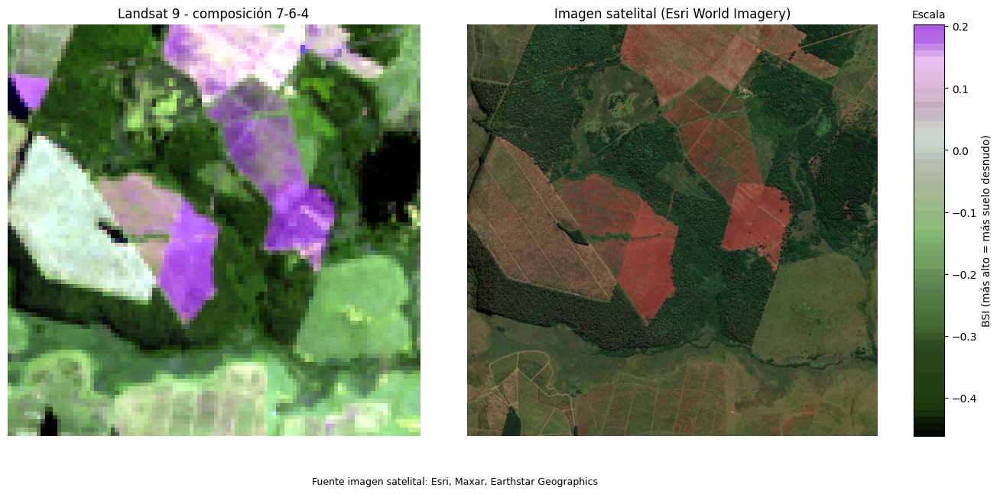

In [14]:
!pip install -q rasterio contextily folium

import rasterio
from rasterio.windows import Window, bounds as win_bounds
from rasterio.warp import transform_bounds
import folium
import contextily as cx
from IPython.display import display

# --- 1) Coordenadas geográficas de la ROI (mismos y0, y1, x0, x1 del recorte) ---
with rasterio.open(BASE.format(4)) as src:
    win = Window(x0, y0, x1 - x0, y1 - y0)
    l, b, r, t = win_bounds(win, src.transform)                # en el CRS de la escena (UTM)
    w, s, e, n = transform_bounds(src.crs, "EPSG:4326", l, b, r, t)

print(f"CRS de la escena: {src.crs}")
print(f"ROI -> lat: {s:.4f} a {n:.4f} | lon: {w:.4f} a {e:.4f}")

# Composición a comparar (la 7-6-4 de suelos)
comp = rgb(roi[7], roi[6], roi[4])

# --- 2) Mapa interactivo: capa satelital de Esri + composición superpuesta ---
m = folium.Map(
    location=[(s + n) / 2, (w + e) / 2],
    zoom_start=13,
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics",
)
folium.raster_layers.ImageOverlay(
    image=comp, bounds=[[s, w], [n, e]], opacity=0.7, name="Composición 7-6-4"
).add_to(m)
folium.Rectangle([[s, w], [n, e]], color="red", weight=2, fill=False, name="ROI").add_to(m)
folium.LayerControl().add_to(m)
display(m)   # usá el control de capas para prender/apagar la composición

# --- 3) Imagen satelital recortada a la ROI ---
cx.tile._clear_cache()
cx.tile.USER_AGENT = "LabMultiespectral-UNaM/1.0 (estudiante UNaM; uso academico)"

img_sat, ext = cx.bounds2img(w, s, e, n, ll=True, source=cx.providers.Esri.WorldImagery)

xmin, xmax, ymin, ymax = ext                                   # extent del mosaico (EPSG:3857)
rx0, ry0, rx1, ry1 = transform_bounds("EPSG:4326", "EPSG:3857", w, s, e, n)
H, W = img_sat.shape[:2]
c0 = int(round((rx0 - xmin) / (xmax - xmin) * W))
c1 = int(round((rx1 - xmin) / (xmax - xmin) * W))
f0 = int(round((ymax - ry1) / (ymax - ymin) * H))
f1 = int(round((ymax - ry0) / (ymax - ymin) * H))
img_sat = img_sat[f0:f1, c0:c1, :3]

# --- 4) Escala empírica: color medio de la composición según el BSI ---
def refl(b):
    return b.astype(np.float32) * 0.0000275 - 0.2

blue_, red_, nir_, swir1_ = (refl(roi[k]) for k in (2, 4, 5, 6))
bsi = ((swir1_ + red_) - (nir_ + blue_)) / ((swir1_ + red_) + (nir_ + blue_) + 1e-6)
valid_ = np.all([roi[k] > 0 for k in (2, 4, 5, 6, 7)], axis=0)       # excluye nodata

comp_f = comp.astype(np.float32) / 255 if comp.dtype == np.uint8 else comp.astype(np.float32)

lo, hi = np.percentile(bsi[valid_], [1, 99])                    # rango sin outliers
nb = 64                                                         # niveles de la barra
edges = np.linspace(lo, hi, nb + 1)
centros = (edges[:-1] + edges[1:]) / 2
idx = np.clip(np.digitize(bsi, edges) - 1, 0, nb - 1)

strip = np.full((nb, 3), np.nan)
for i in range(nb):
    sel = valid_ & (idx == i)
    if sel.sum() >= 50:                                         # mínimo de píxeles por nivel
        strip[i] = comp_f[sel].mean(axis=0)
ok = ~np.isnan(strip[:, 0])
for c in range(3):                                              # rellena niveles con pocos datos
    strip[:, c] = np.interp(centros, centros[ok], strip[ok, c])

# --- 5) Figura comparativa con la escala al costado ---
fig = plt.figure(figsize=(16, 7))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 0.07], wspace=0.08)
ax0, ax1, axb = (fig.add_subplot(gs[0, i]) for i in range(3))

ax0.imshow(comp);    ax0.set_title("Landsat 9 - composición 7-6-4")
ax1.imshow(img_sat); ax1.set_title("Imagen satelital (Esri World Imagery)")
for ax in (ax0, ax1): ax.axis("off")

axb.imshow(strip[::-1][:, None, :], aspect="auto", extent=[0, 1, edges[0], edges[-1]])
axb.set_xticks([])
axb.yaxis.tick_right(); axb.yaxis.set_label_position("right")
axb.set_ylabel("BSI (más alto = más suelo desnudo)")
axb.set_title("Escala", fontsize=10)

fig.text(0.5, 0.02, "Fuente imagen satelital: Esri, Maxar, Earthstar Geographics",
         ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("roi_vs_satelite.png", dpi=200, bbox_inches="tight")
plt.show()

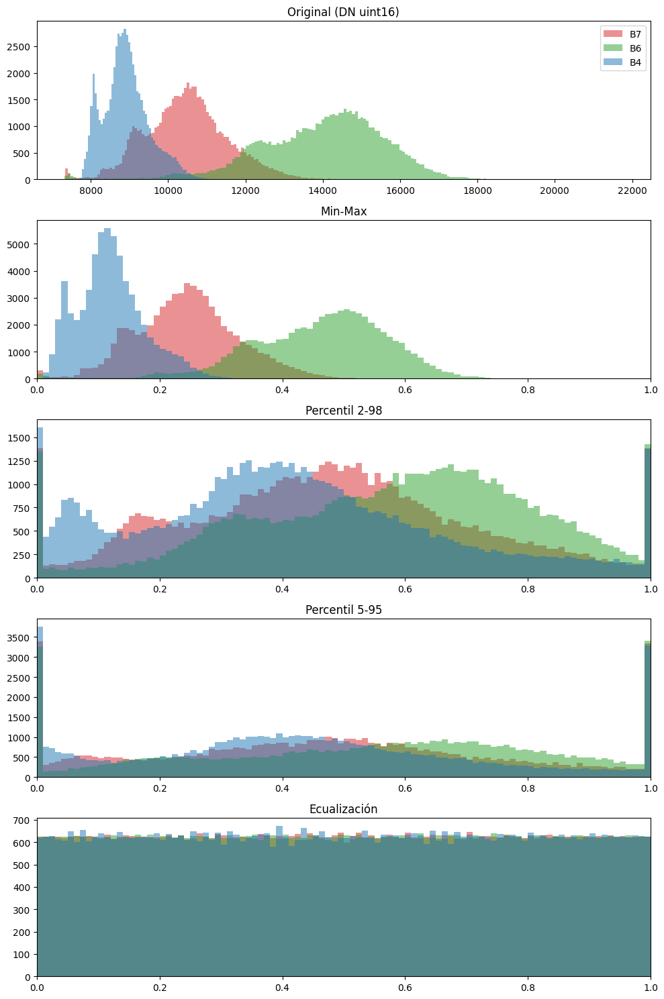

In [ ]:
def histogramas(nombre_comp, metodos=("Min-Max", "Percentil 2-98", "Percentil 5-95", "Ecualización")):
    comp = COMPOSICIONES[nombre_comp]
    colores = ["tab:red", "tab:green", "tab:blue"]
    fig, axs = plt.subplots(1 + len(metodos), 1, figsize=(10, 3 * (1 + len(metodos))))
    for n, c in zip(comp, colores):                                   # original (DN)
        axs[0].hist(roi[n][valid], bins=200, color=c, alpha=0.5, label=f"B{n}")
    axs[0].set_title("Original (DN uint16)"); axs[0].legend()
    for ax, m in zip(axs[1:], metodos):
        img = componer(comp, m)
        for i, c in enumerate(colores):
            ax.hist(img[..., i][valid], bins=100, color=c, alpha=0.5)
        ax.set_title(m); ax.set_xlim(0, 1)
    plt.tight_layout(); plt.show()

histogramas("7-6-4 falso color")

ROI -> lat: -27.5973 a -27.5290 | lon: -55.8933 a -55.8167
Zoom de teselas: 15


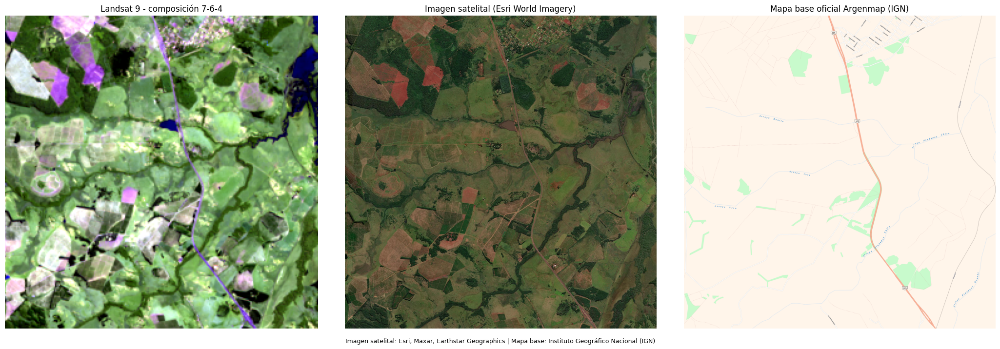


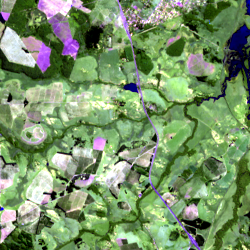

World Imagery: fechas={'DATE (YYYYMMDD)': '20240420', 'SRC_DATE2': '4/20/2024'} | {'RESOLUTION (M)': '0.31', 'SOURCE_INFO': 'Vivid', 'SOURCE': 'Vantor'}
Low Resolution 15m Imagery: fechas={} | {'RESOLUTION (M)': '15', 'SOURCE': 'Earthstar Geographics', 'SOURCE_INFO': 'TerraColor NextGen'}
Citations: fechas={} | {'RESOLUTION (M)': '15', 'SOURCE_INFO': 'TerraColor NextGen', 'SOURCE': 'Earthstar Geographics'}
Citations: fechas={'DATE (YYYYMMDD)': '20240420', 'DATE': '4/20/2024'} | {'RESOLUTION (M)': '0.31', 'SOURCE_INFO': 'Vivid', 'SOURCE': 'Vantor'}
1.2m Resolution Metadata: fechas={'SRC_DATE': '20240420', 'SRC_DATE2': '4/20/2024'} | {'SRC_RES': '0.31', 'SAMP_RES': '1.2', 'NICE_NAME': 'Vivid'}
2.4m Resolution Metadata: fechas={'SRC_DATE': '20240420', 'SRC_DATE2': '4/20/2024'} | {'SRC_RES': '0.31', 'SAMP_RES': '1.2', 'NICE_NAME': 'Vivid'}
4.8m Resolution Metadata: fechas={'SRC_DATE': '20240420', 'SRC_DATE2': '4/20/2024'} | {'SRC_RES': '0.31', 'SAMP_RES': '1.2', 'NICE_NAME': 'Vivid'}
9.6m 

In [ ]:
import io, math, requests
from datetime import datetime, timezone
from PIL import Image
import rasterio
from rasterio.windows import Window, bounds as win_bounds
from rasterio.warp import transform_bounds
import folium
from IPython.display import display

# ---------- 1) ROI en lat/lon (mismos y0, y1, x0, x1 del recorte) ----------
with rasterio.open(BASE.format(4)) as src:
    win = Window(x0, y0, x1 - x0, y1 - y0)
    l, b, r, t = win_bounds(win, src.transform)
    w, s, e, n = transform_bounds(src.crs, "EPSG:4326", l, b, r, t)
print(f"ROI -> lat: {s:.4f} a {n:.4f} | lon: {w:.4f} a {e:.4f}")

comp = componer(COMPOSICIONES["7-6-4 falso color"], "Percentil 2-98")

# ---------- 2) Fuentes de tiles ----------
HEADERS = {"User-Agent": "LabMultiespectral-UNaM/1.0 (estudiante UNaM; uso academico)"}
ESRI_URL = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
IGN_URL  = "https://wms.ign.gob.ar/geoserver/gwc/service/tms/1.0.0/capabaseargenmap@EPSG%3A3857@png/{z}/{x}/{y}.png"
FUENTES = {
    "esri": {"url": ESRI_URL, "tms": False},   # esquema XYZ
    "ign":  {"url": IGN_URL,  "tms": True},    # TMS: el eje Y va invertido ({-y})
}
ZOOM_EXTRA = 0   # subilo a 1 o 2 para más detalle (más tiles descargados)

def lonlat2tile(lon, lat, z):
    k = 2 ** z
    x = (lon + 180) / 360 * k
    y = (1 - math.asinh(math.tan(math.radians(lat))) / math.pi) / 2 * k
    return x, y

def mosaico(w, s, e, n, z, fuente):
    f = FUENTES[fuente]
    fx0, fy0 = lonlat2tile(w, n, z)
    fx1, fy1 = lonlat2tile(e, s, z)
    tx0, tx1, ty0, ty1 = int(fx0), int(fx1), int(fy0), int(fy1)
    img = Image.new("RGB", ((tx1 - tx0 + 1) * 256, (ty1 - ty0 + 1) * 256))
    for tx in range(tx0, tx1 + 1):
        for ty in range(ty0, ty1 + 1):
            y = (2 ** z - 1 - ty) if f["tms"] else ty
            resp = requests.get(f["url"].format(z=z, x=tx, y=y), headers=HEADERS, timeout=30)
            resp.raise_for_status()
            tile = Image.open(io.BytesIO(resp.content)).convert("RGB").resize((256, 256))
            img.paste(tile, ((tx - tx0) * 256, (ty - ty0) * 256))
    caja = (int((fx0 - tx0) * 256), int((fy0 - ty0) * 256),
            int((fx1 - tx0) * 256), int((fy1 - ty0) * 256))
    return np.array(img.crop(caja))

# Zoom automático: ~1000 px de ancho para la ROI (IGN admite de 3 a 18)
z = int(np.clip(math.ceil(math.log2(1000 * 360 / (256 * (e - w)))) + ZOOM_EXTRA, 3, 17))
print(f"Zoom de teselas: {z}")

# ---------- 3) Comparación estática de 3 paneles ----------
img_esri = mosaico(w, s, e, n, z, "esri")
try:
    img_ign = mosaico(w, s, e, n, z, "ign")
except Exception as err:
    print("No se pudo descargar el mapa base del IGN:", err)
    img_ign = None

paneles = [(comp, "Landsat 9 - composición 7-6-4"),
           (img_esri, "Imagen satelital (Esri World Imagery)")]
if img_ign is not None:
    paneles.append((img_ign, "Mapa base oficial Argenmap (IGN)"))

fig, axs = plt.subplots(1, len(paneles), figsize=(7 * len(paneles), 7))
for ax, (im, titulo) in zip(np.atleast_1d(axs), paneles):
    ax.imshow(im); ax.set_title(titulo); ax.axis("off")
fig.text(0.5, 0.02,
         "Imagen satelital: Esri, Maxar, Earthstar Geographics | Mapa base: Instituto Geográfico Nacional (IGN)",
         ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("roi_vs_ign_esri.png", dpi=200, bbox_inches="tight")
plt.show()

# ---------- 4) Mapa interactivo: satelital Esri y Argenmap seleccionables ----------
m = folium.Map(location=[(s + n) / 2, (w + e) / 2], zoom_start=13, tiles=None)
folium.TileLayer(tiles=ESRI_URL, attr="Esri, Maxar, Earthstar Geographics",
                 name="Imagen satelital (Esri)").add_to(m)
folium.TileLayer(tiles=IGN_URL.replace("{y}", "{-y}"), attr="Instituto Geográfico Nacional (IGN)",
                 name="Argenmap (IGN)", min_zoom=3, max_zoom=18).add_to(m)
folium.raster_layers.ImageOverlay(image=comp, bounds=[[s, w], [n, e]],
                                  opacity=0.7, name="Composición 7-6-4").add_to(m)
folium.Rectangle([[s, w], [n, e]], color="red", weight=2, fill=False, name="ROI").add_to(m)
folium.LayerControl().add_to(m)
display(m)

# ---------- 5) Fecha de las imágenes satelitales (metadatos de Esri) ----------
def a_fecha(k, v):
    if isinstance(v, (int, float)) and v > 1e11:          # milisegundos desde 1970
        return datetime.fromtimestamp(v / 1000, tz=timezone.utc).strftime("%Y-%m-%d")
    return v

try:
    res = requests.get(
        "https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/identify",
        params={"geometry": f"{(w + e) / 2},{(s + n) / 2}", "geometryType": "esriGeometryPoint",
                "sr": 4326, "layers": "all", "tolerance": 2,
                "mapExtent": f"{w},{s},{e},{n}", "imageDisplay": "800,800,96",
                "returnGeometry": "false", "f": "json"},
        headers=HEADERS, timeout=30).json()
    for r_ in res.get("results", []):
        a = r_.get("attributes", {})
        fechas = {k: a_fecha(k, v) for k, v in a.items()
                  if "DATE" in k.upper() and v not in (None, "", "Null", 99999, "99999")}
        extra = {k: v for k, v in a.items()
                 if any(p in k.upper() for p in ("RES", "SRC_NAME", "SOURCE", "NICE_NAME"))}
        print(f"{r_.get('layerName')}: fechas={fechas} | {extra}")
except Exception as err:
    print("No se pudo consultar el metadato de fecha:", err)

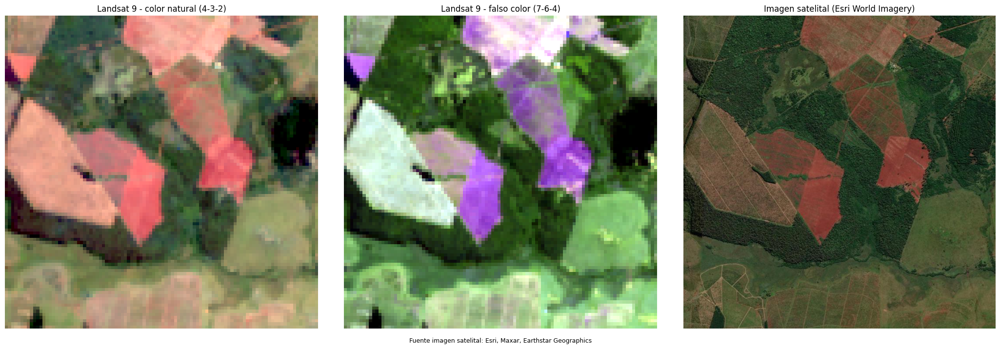

In [15]:
import rasterio
from rasterio.windows import Window, bounds as win_bounds
from rasterio.warp import transform_bounds
import contextily as cx

# ---------- 1) Color natural 4-3-2 con aspecto de imagen satelital ----------
def refl(b):
    return b.astype(np.float32) * 0.0000275 - 0.2

def color_natural(gamma=0.6, p_lo=2, p_hi=98):
    """
    Landsat 4-3-2 (R=Rojo, G=Verde, B=Azul) en reflectancia.
    - Resta el percentil bajo de cada banda (corrección simple de neblina atmosférica,
      porque el azul tiene más dispersión que las demás).
    - Escala los tres canales con el MISMO límite superior para no alterar el balance de color.
    - Aplica gamma < 1 para aclarar los tonos medios: la reflectancia de superficie es baja
      y sin esto la imagen se ve oscura.
    """
    bs = [refl(roi[n]) for n in (4, 3, 2)]
    lo = [np.percentile(b[valid], p_lo) for b in bs]          # por banda
    hi = max(np.percentile(b[valid], p_hi) - l for b, l in zip(bs, lo))   # común
    img = np.dstack([np.clip((b - l) / (hi + 1e-9), 0, 1) for b, l in zip(bs, lo)])
    img = img ** gamma
    img[~valid] = 0
    return img

nat = color_natural(gamma=0.6)                                 # probá gamma entre 0.5 y 0.8
fal = componer(COMPOSICIONES["7-6-4 falso color"], "Percentil 2-98")

# ---------- 2) (Opcional) imagen satelital de Esri recortada a la ROI ----------
USAR_ESRI = True
img_sat = None
if USAR_ESRI:
    try:
        with rasterio.open(BASE.format(4)) as src:
            win = Window(x0, y0, x1 - x0, y1 - y0)
            l_, b_, r_, t_ = win_bounds(win, src.transform)
            w, s, e, n = transform_bounds(src.crs, "EPSG:4326", l_, b_, r_, t_)

        cx.tile._clear_cache()
        cx.tile.USER_AGENT = "LabMultiespectral-UNaM/1.0 (estudiante UNaM; uso academico)"
        img_sat, ext = cx.bounds2img(w, s, e, n, ll=True, source=cx.providers.Esri.WorldImagery)

        xmin, xmax, ymin, ymax = ext
        rx0, ry0, rx1, ry1 = transform_bounds("EPSG:4326", "EPSG:3857", w, s, e, n)
        H, W = img_sat.shape[:2]
        c0 = int(round((rx0 - xmin) / (xmax - xmin) * W))
        c1 = int(round((rx1 - xmin) / (xmax - xmin) * W))
        f0 = int(round((ymax - ry1) / (ymax - ymin) * H))
        f1 = int(round((ymax - ry0) / (ymax - ymin) * H))
        img_sat = img_sat[f0:f1, c0:c1, :3]
    except Exception as err:
        print("No se pudo obtener la imagen de Esri:", err)
        img_sat = None

# ---------- 3) Comparación directa ----------
paneles = [(nat, "Landsat 9 - color natural (4-3-2)"),
           (fal, "Landsat 9 - falso color (7-6-4)")]
if img_sat is not None:
    paneles.append((img_sat, "Imagen satelital (Esri World Imagery)"))

fig, axs = plt.subplots(1, len(paneles), figsize=(7 * len(paneles), 7), squeeze=False)
for ax, (im, titulo) in zip(axs.ravel(), paneles):
    ax.imshow(im); ax.set_title(titulo); ax.axis("off")
if img_sat is not None:
    fig.text(0.5, 0.02, "Fuente imagen satelital: Esri, Maxar, Earthstar Geographics",
             ha="center", fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig("natural_vs_falso_color.png", dpi=200, bbox_inches="tight")
plt.show()